In [23]:
from pathlib import Path
import pandas as pd

caminho_dados = Path("../data/processed")
df_contratos = pd.read_parquet(caminho_dados / "contratos.parquet")
df_itens = pd.read_parquet(caminho_dados / "itens.parquet")

print(f"Contratos: {df_contratos.shape[0]:,} linhas | {df_contratos.shape[1]} colunas")
print(f"Itens: {df_itens.shape[0]:,} linhas | {df_itens.shape[1]} colunas")

Contratos: 130,511 linhas | 27 colunas
Itens: 343,526 linhas | 12 colunas


In [24]:
itens_anomalos = df_itens[df_itens["flag_inconsistencia_preco"]].copy()

colunas_contratos = [
    col for col in ["contratacao","codigo_do_contrato", "unidade", "status_contratacao", "data_contratacao"]
    if col and col in df_contratos.columns
]

auditoria_anomalias = itens_anomalos.merge(
    df_contratos[colunas_contratos],
    on="contratacao",
    how="left"
)

colunas_exibicao = [
    col for col in [
        "contratacao",
        "itens",
        "unidade",
        "vl_unit_original",
        "qtde_original",
        "total_aditivada_suprimida",
        
        "status_contratacao"
    ] if col in auditoria_anomalias.columns
]

display(auditoria_anomalias[colunas_exibicao].head(10))


,contratacao,unidade,vl_unit_original,qtde_original,total_aditivada_suprimida,status_contratacao
0,2022000738,SETRAB - SECRETARIA DE ESTADO DO TRABALHO E RENDA,-0.0003,200.0,0.0,Ativo
1,2022001193,SMGSI - Subsecretaria Militar do Gab de Seg Inst,-0.0003,700.0,0.0,Em Aberto
2,2022001085,SEPOL - Secretaria de Estado de Policia Civil,-0.0003,360.0,0.0,Ativo
3,2022001149,LOTERJ - LOTERIA DO ESTADO DO RIO DE JANEIRO,-0.0003,100.0,0.0,Encerrado
4,2022002393,SEDSODH - SEC ESTADO DESEN SOCIAL E DE DIR HUM,-0.0003,338.0,0.0,Em Aberto
5,2022001442,PGE - PROCURADORIA GERAL DO ESTADO,-0.0003,1000.0,0.0,Ativo
6,2022001275,CEPERJ - FUND CENTRO EST. ESTAT. PESQ. SERV RJ,-0.0003,120.0,0.0,Em Aberto
7,2022004036,"SEELJE - SEC DE EST ESPORTE, LAZER E JUVENTUDE",-0.0003,250.0,0.0,Ativo
8,2022003244,SEPLAG - Secretaria de Estado de Planejamento ...,-0.0003,350.0,0.0,Ativo
9,2022003935,FES - FUNDO ESTADUAL DE SAÚDE,-0.0003,1500.0,1875.0,Ativo


In [25]:
colunas_contratos_detalhe = [
    col for col in [
        "contratacao",
        "codigo_do_contrato",
        "unidade",
        "contratado",
        "cpf_cnpj",
        "valor_total_contrato_valor_estimado_para_contratacao_r",
        "valor_total_liquidado_r",
    ]
    if col in df_contratos.columns
]

detalhe_anomalias = itens_anomalos.merge(
    df_contratos[colunas_contratos_detalhe],
    on="contratacao",
    how="left"
)

colunas_finais = [
    col for col in [
        "contratacao",
        "unidade",
        "contratado",
        "item",
        "vl_unit_original",
        "qtde_original",
        "valor_total_liquidado_r",
    ]
    if col in detalhe_anomalias.columns
]

display(detalhe_anomalias[colunas_finais].head(10))

,contratacao,unidade,item,vl_unit_original,qtde_original,valor_total_liquidado_r
0,2022000738,SETRAB - SECRETARIA DE ESTADO DO TRABALHO E RENDA,SERVICO DE AQUISICAO DE PASSAGENS AEREAS - DES...,-0.0003,200.0,18368.84
1,2022001193,SMGSI - Subsecretaria Militar do Gab de Seg Inst,SERVICO DE AQUISICAO DE PASSAGENS AEREAS - DES...,-0.0003,700.0,155197.63
2,2022001085,SEPOL - Secretaria de Estado de Policia Civil,SERVICO DE AQUISICAO DE PASSAGENS AEREAS - DES...,-0.0003,360.0,NaN
3,2022001149,LOTERJ - LOTERIA DO ESTADO DO RIO DE JANEIRO,SERVICO DE AQUISICAO DE PASSAGENS AEREAS - DES...,-0.0003,100.0,14856.72
4,2022002393,SEDSODH - SEC ESTADO DESEN SOCIAL E DE DIR HUM,SERVICO DE AQUISICAO DE PASSAGENS AEREAS - DES...,-0.0003,338.0,236734.67
5,2022001442,PGE - PROCURADORIA GERAL DO ESTADO,SERVICO DE AQUISICAO DE PASSAGENS AEREAS - DES...,-0.0003,1000.0,307193.03
6,2022001275,CEPERJ - FUND CENTRO EST. ESTAT. PESQ. SERV RJ,SERVICO DE AQUISICAO DE PASSAGENS AEREAS - DES...,-0.0003,120.0,32167.77
7,2022004036,"SEELJE - SEC DE EST ESPORTE, LAZER E JUVENTUDE",SERVICO DE AQUISICAO DE PASSAGENS AEREAS - DES...,-0.0003,250.0,28553.76
8,2022003244,SEPLAG - Secretaria de Estado de Planejamento ...,SERVICO DE AQUISICAO DE PASSAGENS AEREAS - DES...,-0.0003,350.0,120417.10
9,2022003935,FES - FUNDO ESTADUAL DE SAÚDE,SERVICO DE AQUISICAO DE PASSAGENS AEREAS - DES...,-0.0003,1500.0,998862.01


In [26]:
descricao_completa = itens_anomalos["item"].iloc[0]
print(f"Descrição completa do item:\n{descricao_completa}\n")

colunas_fornecedor = [
    c for c in df_contratos.columns
    if any(termo in c.lower() for termo in ["fornec", "razao", "social", "empresa", "favorecido", "cnpj", "cpf"])
]
print("Colunas de fornecedor/identificação disponíveis em contratos:", colunas_fornecedor)

if colunas_fornecedor:
    colunas_cruzamento = ["contratacao", "unidade", "valor_total_liquidado_r"] + colunas_fornecedor
    resumo_passagens = itens_anomalos[["contratacao", "vl_unit_original", "qtde_original"]].merge(
        df_contratos[[c for c in colunas_cruzamento if c in df_contratos.columns]],
        on="contratacao",
        how="left"
    )
    display(resumo_passagens.head(5))

Descrição completa do item:
SERVICO DE AQUISICAO DE PASSAGENS AEREAS - DESCRIÇÃO: PRESTAÇÃO DE SERVIÇO DE AGENCIAMENTO DE VIAGENS, COMPREENDENDO O FORNECIMENTO DE PASSAGENS AÉREAS NACIONAIS E INTERNACIONAIS, RESERVA, EMISSÃO, MARCAÇÃO, ENDOSSO, ENTREGA DE BILHETES, RESERVA DE HOTEIS E SERVIÇOS CORRELATOS.

Colunas de fornecedor/identificação disponíveis em contratos: ['fornecedor', 'cpf_cnpj']


,contratacao,vl_unit_original,qtde_original,unidade,valor_total_liquidado_r,fornecedor,cpf_cnpj
0,2022000738,-0.0003,200.0,SETRAB - SECRETARIA DE ESTADO DO TRABALHO E RENDA,18368.84,WEBTRIP AGÊNCIA DE VIAGENS E TURISMO EIRELI,07.340.993/0001-90
1,2022001193,-0.0003,700.0,SMGSI - Subsecretaria Militar do Gab de Seg Inst,155197.63,WEBTRIP AGÊNCIA DE VIAGENS E TURISMO EIRELI,07.340.993/0001-90
2,2022001085,-0.0003,360.0,SEPOL - Secretaria de Estado de Policia Civil,NaN,WEBTRIP AGÊNCIA DE VIAGENS E TURISMO EIRELI,07.340.993/0001-90
3,2022001149,-0.0003,100.0,LOTERJ - LOTERIA DO ESTADO DO RIO DE JANEIRO,14856.72,WEBTRIP AGÊNCIA DE VIAGENS E TURISMO EIRELI,07.340.993/0001-90
4,2022002393,-0.0003,338.0,SEDSODH - SEC ESTADO DESEN SOCIAL E DE DIR HUM,236734.67,WEBTRIP AGÊNCIA DE VIAGENS E TURISMO EIRELI,07.340.993/0001-90


In [27]:
# ==============================================================================
# AUDITORIA DE DUPLICATAS, NULOS E INTEGRIDADE REFERENCIAL (1:N)
# ==============================================================================

duplicadas_contratos = df_contratos.duplicated().sum()
duplicadas_itens = df_itens.duplicated().sum()
unicidade_chave_contratos = df_contratos["contratacao"].is_unique

print("=== 1. AUDITORIA DE DUPLICATAS ===")
print(f"Linhas integralmente duplicadas em Contratos: {duplicadas_contratos}")
print(f"Linhas integralmente duplicadas em Itens: {duplicadas_itens}")
print(f"A chave 'contratacao' é estritamente única em Contratos (PK)? {'Sim' if unicidade_chave_contratos else 'Não'}")

print("\n=== 2. DIAGNÓSTICO DE VALORES NULOS (CONTRATOS) ===")
cols_financeiras = [
    c for c in [
        "valor_total_contrato_valor_estimado_para_contratacao_r",
        "valor_total_empenhado_r", 
        "valor_total_liquidado_r", 
        "valor_total_pago_r"
    ] if c in df_contratos.columns
]
nulos_fin = df_contratos[cols_financeiras].isna().sum()
pct_nulos = (df_contratos[cols_financeiras].isna().mean() * 100).round(2)
resumo_nulos = pd.DataFrame({"Qtd Nulos": nulos_fin, "% Nulos": pct_nulos})
display(resumo_nulos)

print("\n=== 3. INTEGRIDADE REFERENCIAL (CONTRATOS x ITENS) ===")
chaves_c = set(df_contratos["contratacao"].dropna())
chaves_i = set(df_itens["contratacao"].dropna())

itens_orfaos = (~df_itens["contratacao"].isin(chaves_c)).sum()
taxa_aderencia_itens = ((len(df_itens) - itens_orfaos) / len(df_itens)) * 100
contratos_sem_itens = (~df_contratos["contratacao"].isin(chaves_i)).sum()

print(f"Total de itens na base: {len(df_itens):,}".replace(",", "."))
print(f"Itens com contrato pai correspondente: {len(df_itens) - itens_orfaos:,} ({taxa_aderencia_itens:.2f}%)".replace(",", "."))
print(f"Itens órfãos (sem chave em contratos): {itens_orfaos}")
print(f"Contratos sem itens discriminados: {contratos_sem_itens:,} de {len(df_contratos):,}".replace(",", "."))

=== 1. AUDITORIA DE DUPLICATAS ===
Linhas integralmente duplicadas em Contratos: 0
Linhas integralmente duplicadas em Itens: 0
A chave 'contratacao' é estritamente única em Contratos (PK)? Sim

=== 2. DIAGNÓSTICO DE VALORES NULOS (CONTRATOS) ===


,Qtd Nulos,% Nulos
valor_total_contrato_valor_estimado_para_contratacao_r,0,0.00
valor_total_empenhado_r,74974,57.45
valor_total_liquidado_r,90921,69.67
valor_total_pago_r,93176,71.39



=== 3. INTEGRIDADE REFERENCIAL (CONTRATOS x ITENS) ===
Total de itens na base: 343.526
Itens com contrato pai correspondente: 343.526 (100.00%)
Itens órfãos (sem chave em contratos): 0
Contratos sem itens discriminados: 0 de 130.511


In [28]:
# Investigação das 747 duplicatas identificadas na auditoria de itens
# Objetivo: verificar se representam redundância idêntica do extrator antes do drop_duplicates
itens_duplicados = df_itens[df_itens.duplicated(keep=False)].sort_values(by=["contratacao", "item"])

print(f"=== INSPEÇÃO DE DUPLICATAS: {len(itens_duplicados)} REGISTROS ENVOLVIDOS ===")
display(itens_duplicados[["contratacao", "item", "qtde_original", "vl_unit_original", "total_aditivada_suprimida"]].head(10))

=== INSPEÇÃO DE DUPLICATAS: 0 REGISTROS ENVOLVIDOS ===


,contratacao,item,qtde_original,vl_unit_original,total_aditivada_suprimida


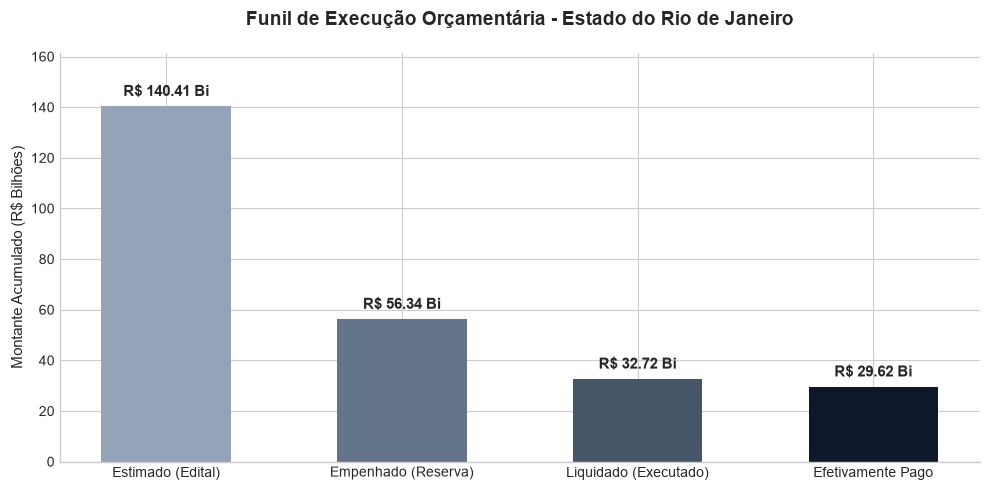

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, ax = plt.subplots(figsize=(10, 5))

totais_orcamento = {
    "Estimado (Edital)": df_contratos["valor_total_contrato_valor_estimado_para_contratacao_r"].sum(),
    "Empenhado (Reserva)": df_contratos["valor_total_empenhado_r"].sum(),
    "Liquidado (Executado)": df_contratos["valor_total_liquidado_r"].sum(),
    "Efetivamente Pago": df_contratos["valor_total_pago_r"].sum(),
}

etapas = list(totais_orcamento.keys())
valores_bi = [v / 1e9 for v in totais_orcamento.values()]

# Gradiente corporativo: do azul marinho profundo ao azul médio
cores = ["#94A3B8", "#64748B", "#475569", "#0F172A"]
barras = ax.bar(etapas, valores_bi, color=cores, width=0.55)

for barra in barras:
    altura = barra.get_height()
    ax.annotate(
        f"R$ {altura:.2f} Bi",
        xy=(barra.get_x() + barra.get_width() / 2, altura),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title("Funil de Execução Orçamentária - Estado do Rio de Janeiro", fontsize=14, fontweight="bold", pad=20)
ax.set_ylabel("Montante Acumulado (R$ Bilhões)", fontsize=11)
ax.set_ylim(0, max(valores_bi) * 1.15)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

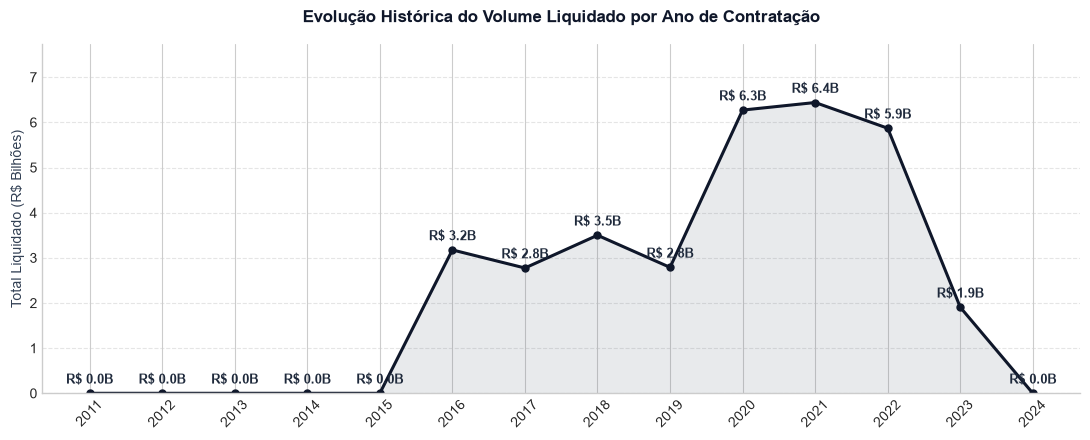

In [ ]:
import matplotlib.pyplot as plt

# ==============================================================================
# SÉRIE TEMPORAL: EVOLUÇÃO ANUAL DAS DESPESAS PÚBLICAS LIQUIDADAS
# ==============================================================================

df_contratos["ano_contratacao"] = df_contratos["data_contratacao"].dt.year

historico_anual = (
    df_contratos.dropna(subset=["ano_contratacao"])
    .groupby("ano_contratacao")["valor_total_liquidado_r"]
    .sum()
    .reset_index()
)
historico_anual = historico_anual.query("2010 <= ano_contratacao <= 2024").sort_values("ano_contratacao")

fig, ax = plt.subplots(figsize=(11, 4.5))

anos = historico_anual["ano_contratacao"].astype(int).astype(str)
valores_bi = historico_anual["valor_total_liquidado_r"] / 1e9

ax.plot(anos, valores_bi, marker="o", color="#0F172A", linewidth=2.2, markersize=5)
ax.fill_between(anos, valores_bi, color="#475569", alpha=0.12)

for i, txt in enumerate(valores_bi):
    ax.annotate(
        f"R$ {txt:.1f}B",
        (anos.iloc[i], valores_bi.iloc[i]),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="#1E293B"
    )

ax.set_title("Evolução Histórica do Volume Liquidado por Ano de Contratação", fontsize=12, fontweight="bold", pad=16, color="#0F172A")
ax.set_ylabel("Total Liquidado (R$ Bilhões)", fontsize=10, color="#334155")
ax.set_ylim(0, max(valores_bi) * 1.2)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# Curva ABC: Top 10 Fornecedores por Volume Liquidado no Estado do RJ
# ==============================================================================

top_fornecedores = (
    df_contratos.dropna(subset=["fornecedor"])
    .groupby("fornecedor")["valor_total_liquidado_r"]
    .sum()
    .reset_index()
    .sort_values(by="valor_total_liquidado_r", ascending=False)
)

total_liquidado = df_contratos["valor_total_liquidado_r"].sum()
top_fornecedores["pct_total"] = (top_fornecedores["valor_total_liquidado_r"] / total_liquidado) * 100
top_fornecedores["pct_acumulado"] = top_fornecedores["pct_total"].cumsum()

top_10 = top_fornecedores.head(10).copy()
top_10["valor_bi"] = top_10["valor_total_liquidado_r"] / 1e9

tabela_visual = pd.DataFrame({
    "Fornecedor / Razão Social": top_10["fornecedor"],
    "Liquidado (R$ Bi)": top_10["valor_bi"].apply(lambda v: f"R$ {v:.2f}B"),
    "% do Total": top_10["pct_total"].apply(lambda p: f"{p:.2f}%"),
    "% Acumulado": top_10["pct_acumulado"].apply(lambda a: f"{a:.2f}%")
})
display(tabela_visual)

fig, ax = plt.subplots(figsize=(11, 5.5))
barras = ax.barh(top_10["fornecedor"][::-1], top_10["valor_bi"][::-1], color="#0F172A", height=0.6)

for barra in barras:
    largura = barra.get_width()
    ax.annotate(
        f"R$ {largura:.2f}B",
        xy=(largura, barra.get_y() + barra.get_height() / 2),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="#1E293B"
    )

ax.set_title("Top 10 Fornecedores por Volume Financeiro Liquidado", fontsize=12, fontweight="bold", pad=16, color="#0F172A")
ax.set_xlabel("Total Liquidado (R$ Bilhões)", fontsize=10, color="#334155")
ax.set_xlim(0, max(top_10["valor_bi"]) * 1.15)
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.savefig("../docs/curva_abc.png", dpi=300, bbox_inches="tight")
plt.show()

NameError: name 'df_contratos' is not defined

In [2]:
# ==============================================================================
# Análise de Volume e Frequência por Tipo de Aquisição (Modalidade)
# ==============================================================================


modalidades = (
    df_contratos.dropna(subset=["tipo_de_aquisicao"])
    .groupby("tipo_de_aquisicao")
    .agg(
        qtd_contratos=("contratacao", "count"),
        total_liquidado=("valor_total_liquidado_r", "sum")
    )
    .reset_index()
    .sort_values(by="total_liquidado", ascending=False)
)

total_geral_liquidado = df_contratos["valor_total_liquidado_r"].sum()
modalidades["pct_liquidado"] = (modalidades["total_liquidado"] / total_geral_liquidado) * 100
modalidades["total_bi"] = modalidades["total_liquidado"] / 1e9

tabela_modalidades = pd.DataFrame({
    "Tipo de Aquisição": modalidades["tipo_de_aquisicao"],
    "Contratos": modalidades["qtd_contratos"].apply(lambda q: f"{q:,}".replace(",", ".")),
    "Liquidado (R$ Bi)": modalidades["total_bi"].apply(lambda v: f"R$ {v:.2f}B"),
    "% do Total": modalidades["pct_liquidado"].apply(lambda p: f"{p:.2f}%")
})
display(tabela_modalidades.head(8))

top_modalidades = modalidades.head(6)

fig, ax = plt.subplots(figsize=(11, 4.5))
barras = ax.barh(top_modalidades["tipo_de_aquisicao"][::-1], top_modalidades["total_bi"][::-1], color="#0F172A", height=0.55)

for barra in barras:
    largura = barra.get_width()
    ax.annotate(
        f"R$ {largura:.2f}B",
        xy=(largura, barra.get_y() + barra.get_height() / 2),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="#1E293B"
    )

ax.set_title("Volume Financeiro Liquidado por Tipo de Aquisição", fontsize=12, fontweight="bold", pad=16, color="#0F172A")
ax.set_xlabel("Total Liquidado (R$ Bilhões)", fontsize=10, color="#334155")
ax.set_xlim(0, max(top_modalidades["total_bi"]) * 1.15)
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.savefig("../docs/modalidades_aquisicao.png", dpi=300, bbox_inches="tight")
plt.show()

NameError: name 'df_contratos' is not defined